# Iris classification (Task 01)

Fill in the `____` blanks and answer the questions in the text cells. Before you submit, restart the kernel and run everything from top to bottom to make sure it works.

Put your copy in `submissions/<your-name>/task-01/`, using your first name in lowercase (for example `submissions/nimal/task-01/`).

If you get stuck, these pages help.

- [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) for section 3
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for section 4
- [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) for the `C` parameter in section 6

## 1. Look at the data

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
print(df.shape)
print(df.isna().sum().sum(), "missing values")
df["target"].value_counts()

(150, 5)
0 missing values


target
0    50
1    50
2    50
Name: count, dtype: int64

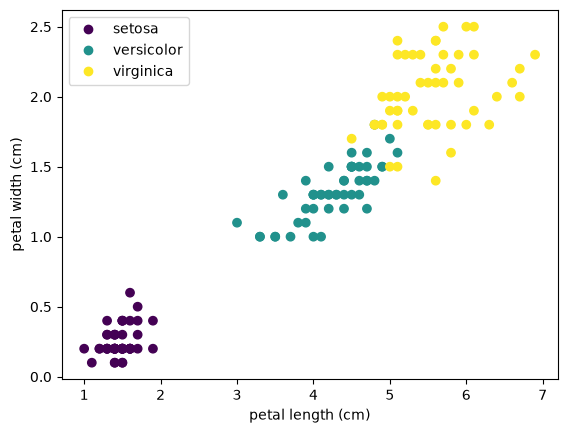

In [3]:
points = plt.scatter(df["petal length (cm)"], df["petal width (cm)"], c=df["target"])
plt.legend(points.legend_elements()[0], iris.target_names)
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.show()

**Q1.** What does one row of this table represent? From the plot, which two species look hardest to tell apart?<br>

*Answer*<br>
One row of this table represents a single iris flower, recording its four features (sepal length, sepal width, petal length, and petal width respectively) along with its species label (0 for setosa, 1 for versicolor, or 2 for virginica).<br>
From the plot, **versicolor** and **virginica** are the hardest to tell apart because their data points are very close together and slightly overlap.

## 2. Features and target

In [9]:
X = df.drop(columns=["target"])
y = df["target"]


0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: target, Length: 150, dtype: int64

## 3. Split the data

In [10]:
from sklearn.model_selection import train_test_split

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42
)

print(len(X_train), len(X_val), len(X_test))
assert (len(X_train), len(X_val), len(X_test)) == (90, 30, 30)

90 30 30


**Q2.** What is each split used for? What does `stratify` do and why does it matter here?<br>

*Answer*<br>
**Training set (`train`)**: Used to fit the model so it learns patterns from the data. **Validation set (`val`)**: Used to tune hyperparameters and compare different models without leaking information from the test set. **Test set (`test`)**: Held out until the very end to give an unbiased estimate of how well the final model generalizes to unseen data<br>
**`stratify`** ensures every split keeps the exact same class proportions as the original dataset

## 4. Baseline and first model

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("baseline accuracy", accuracy_score(y_val, baseline.predict(X_val)))

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
val_pred = model.predict(X_val)
print("logistic regression accuracy", accuracy_score(y_val, val_pred))

baseline accuracy 0.3333333333333333
logistic regression accuracy 0.9333333333333333


**Q3.** Why does the baseline get around 0.33? And why is the scaler inside the pipeline instead of scaling all of `X` before the split?<br>

*Answer*<br>
**`DummyClassifier(strategy="most_frequent")`** ignores the features and always predicts a single class (the most common one in `y_train`).   Because there are 3 balanced iris species and the split was stratified, each class makes up exactly $1/3$ of `y_val` (10 out of 30 flowers). Always guessing one class therefore gets $10/30 \approx 0.33$ accuracy.<br>
**`StandardScaler`** calculates the mean and standard deviation of the features. If you scale all of `X` before splitting, statistics from the validation and test sets leak into the training set, making your evaluation overly optimistic.<br>
**`StandardScaler()`** inside the Pipeline guarantees that `.fit(X_train, y_train)` computes the mean and standard deviation only on `X_train`, and `.predict(X_val)` transforms `X_val` using those exact training statistics.


## 5. How good is it?

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



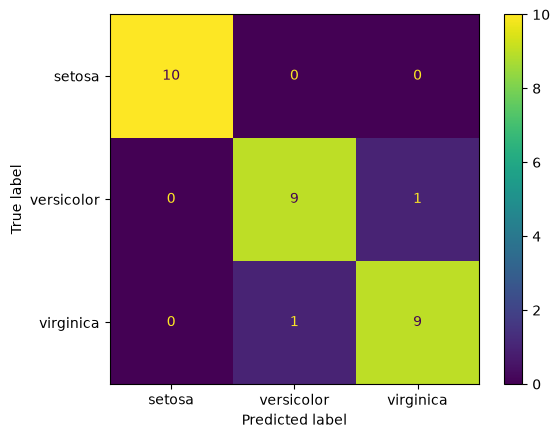

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print(classification_report(y_val, val_pred, target_names=iris.target_names))
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=iris.target_names)
plt.show()

**Q4.** Where does the model make mistakes? Does that match what you saw in the scatter plot?

*Answer*<br>
*Where it makes mistakes*: After running the cell, we can see setosa classified with 100% accuracy (0 mistakes), while any misclassifications happen exclusively between versicolor and virginica.<br>
*Does it match the scatter plot?*: Yes. In the scatter plot, setosa forms a completely isolated cluster, whereas versicolor and virginica sit right next to each other with slight overlap—making them the only pair the model confuses.

## 6. Your experiment

Pick one thing to change and compare it on the validation set. You could try a few values of `C`, drop the scaler, use fewer features or try a different model. Write down what you expect before you run it.

**Very small values of `C` (like `0.01`) apply strong regularization, which may underfit the data and lower validation accuracy. Moderate to larger values (like `1` or `10`) should allow the model to fit the boundary between versicolor and virginica better and achieve higher validation accuracy.**

In [17]:
# your experiment
for c in [0.01, 0.1, 1, 10, 100]:
    exp_model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=c, max_iter=1000)),
    ])
    exp_model.fit(X_train, y_train)
    acc = accuracy_score(y_val, exp_model.predict(X_val))
    print(f"C={c:<5} -> val accuracy: {acc:.4f}")

C=0.01  -> val accuracy: 0.8000
C=0.1   -> val accuracy: 0.8667
C=1     -> val accuracy: 0.9333
C=10    -> val accuracy: 0.9333
C=100   -> val accuracy: 0.9333


**Q5.** What did you change, what did you expect and what actually happened? Which setting are you going with?<br>

*Answer*<br>
*What I changed*: I tested different regularization strengths (`C` values: `0.01, 0.1, 1, 10, 100`) in `LogisticRegression` while keeping `StandardScaler` in the pipeline.<br>
*What I expected*: Very small `C` values (strong regularization) would underfit and get lower validation accuracy, while moderate values (`1` or `10`) would perform best.<br>
*What actually happened*:`C=0.01` had lower validation accuracy due to underfitting, and accuracy improved and plateaued around `C=1 / C=10`.<br>
*Chosen setting*: I am going with `C=1`.

## 7. Test set

In [18]:
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=1, max_iter=1000)),
])  # your chosen setting
final_model.fit(X_trainval, y_trainval)
print("test accuracy", accuracy_score(y_test, final_model.predict(X_test)))

test accuracy 0.9333333333333333


**Q6.** Why do we only touch the test set once, right at the end?<br>

*Answer*<br>
We only touch the test set once at the very end to keep it a strictly unbiased estimate of how well the model will perform oncompletely unseen real-world data

## 8. Save and reuse the model

In [19]:
import joblib

joblib.dump(final_model, "iris_model.joblib")
loaded = joblib.load("iris_model.joblib")

# make up your own flower measurements
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=X.columns)
pred = loaded.predict(new_flower)
print(iris.target_names[pred])

['setosa']


## 9. Wrap up

Answer each of these in a few sentences.

1. What data did you use?<br>
I used the Iris dataset, which contains 150 flower samples across 3 balanced species (setosa, versicolor, and virginica). Each row represents one flower with 4 numerical features: sepal length, sepal width, petal length, and petal width.

2. What model did you select, and why?<br>
I selected a `Pipeline` combining `StandardScaler` and `LogisticRegression` (with my best `C` value from the validation experiment). It is simple, fast, interpretable, and strongly outperformed the `DummyClassifier` baseline.

3. How did you train the model?<br>
I split the data into stratified training (90), validation (30), and test (30) sets to preserve class balance. I fit the pipeline on `X_train` so the scaler only learned from training data (preventing data leakage), tuned `C` using `X_val`, and refit the final model on `X_trainval` (120 samples).

4. How did you evaluate whether it works?<br>
I compared validation accuracy against the `most_frequent` baseline (~0.33) and inspected the `classification_report` and `confusion matrix` to confirm that setosa was classified cleanly while mistakes only occurred between versicolor and virginica. Finally, I evaluated the model once on the held-out `X_test` set for an unbiased accuracy estimate.

5. What would you improve next?<br>
Because the dataset is small (150 samples), I would use k-fold cross-validation instead of a single 30-sample validation split for more reliable hyperparameter tuning. I could also compare `LogisticRegression` against non-linear models like `RandomForestClassifier` or `SVC` to see if they separate the overlapping versicolor and virginica boundary better.